# PharmaFlow Foundation — Session 2.3 Solutions
### Visualisation with matplotlib & Seaborn

These are the instructor solutions for all six exercise tiers. Every cell below has
been run for real, and every chart and number shown is actual output.

**Data:** the same files as Session 2.2, all in `data/raw/`: `adverse_events_10k.csv`
(6,218 reports), `drug_reference.csv` and `reaction_categories.csv`. Charts are saved
as files in `data/processed/charts/`, the folder this course uses for everything a
pipeline produces.

**Versions:** pandas 3.0.5, matplotlib 3.11.2, seaborn 0.13.2.

**Colours used throughout:** blue `#2E74B5` for the data, terracotta `#C0392B` to
highlight one thing, gray `#9AA5B1` for context. When several series need their own
colours, they take blue, terracotta and purple `#7B5EA7`, always in that order. That
set was run through a colour-blindness check; terracotta with a green failed it, which
is why there is no green.


## Before You Run Anything — Environment Check

Same setup pattern as every session, plus two new libraries. If the check prints
`No module named 'matplotlib'` or `'seaborn'`, run `pip install --user -r requirements.txt`
in the terminal once and restart the kernel.


In [1]:
# --- Setup check: always run this cell first ---
import os
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

def find_repo_root(marker_folder="data", start=None):
    """
    Different notebook tools start a notebook's kernel in different folders,
    so we search upward from wherever we happened to start until we find a
    folder that contains `data` -- that only exists at the repo root, so
    wherever we find it IS the repo root.
    """
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError(
                f"Could not find a '{marker_folder}' folder anywhere above "
                f"{os.getcwd()}. Make sure this notebook is somewhere inside "
                f"the pharmaflow-ai repo."
            )
        current = parent


REPO_ROOT = find_repo_root()
RAW = os.path.join(REPO_ROOT, "data", "raw")
CHART_DIR = os.path.join(REPO_ROOT, "data", "processed", "charts")
os.makedirs(CHART_DIR, exist_ok=True)

BLUE, HIGHLIGHT, CONTEXT = "#2E74B5", "#C0392B", "#9AA5B1"
SERIES = ["#2E74B5", "#C0392B", "#7B5EA7"]   # checked for colour blindness, in this order
pd.set_option("display.width", 120)

print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__)
needed = ["adverse_events_10k.csv", "drug_reference.csv", "reaction_categories.csv"]
missing = [f for f in needed if not os.path.exists(os.path.join(RAW, f))]
print("Missing files:", missing if missing else "none. You're ready to go.")


pandas 3.0.5 | matplotlib 3.11.2 | seaborn 0.13.2
Missing files: none. You're ready to go.


## Warm-Up — The chai stall chain, drawn (no FDA data yet)

The Session 2.2 chai stalls again: monthly cups per stall. One figure, two charts
side by side: a bar chart to compare stalls in one month, and a line chart to show
each stall over time. Then save it and check the file exists.


          S1   S2  S3
2026-01  160  120  60
2026-02  150   45  80
2026-03  175   60  95

saved: warmup_chai_stalls.png | exists: True
axes in the figure: 2


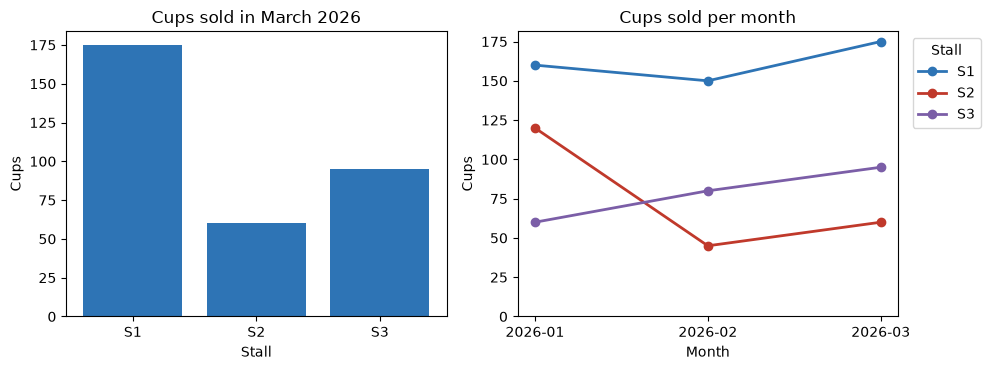

In [2]:
# WARM-UP: the anatomy of a figure -- fig is the whole picture, each ax is one chart.
monthly = pd.DataFrame(
    {"S1": [160, 150, 175], "S2": [120, 45, 60], "S3": [60, 80, 95]},
    index=["2026-01", "2026-02", "2026-03"],
)
print(monthly)

fig, (ax_bar, ax_line) = plt.subplots(1, 2, figsize=(10, 3.8))

ax_bar.bar(monthly.columns, monthly.loc["2026-03"], color=BLUE)
ax_bar.set_title("Cups sold in March 2026")
ax_bar.set_xlabel("Stall")
ax_bar.set_ylabel("Cups")

for stall, colour in zip(monthly.columns, SERIES):
    ax_line.plot(monthly.index, monthly[stall], marker="o", linewidth=2,
                 color=colour, label=stall)
ax_line.set_title("Cups sold per month")
ax_line.set_xlabel("Month")
ax_line.set_ylabel("Cups")
ax_line.set_ylim(bottom=0)
ax_line.legend(title="Stall", loc="upper left", bbox_to_anchor=(1.02, 1))

fig.tight_layout()
path = os.path.join(CHART_DIR, "warmup_chai_stalls.png")
fig.savefig(path, dpi=150, bbox_inches="tight")
print()
print("saved:", os.path.basename(path), "| exists:", os.path.exists(path))
print("axes in the figure:", len(fig.axes))
plt.show()


## Exercise 1 · Beginner — "Where do our reports come from?"

Regulatory Affairs wants one chart for a slide: the ten biggest sources of reports,
with reports that have no country shown, not hidden. Country codes are short labels
but there are ten of them, so a horizontal bar chart, sorted, with the count written
at the end of each bar.


country
US              4234
Not reported     403
GB               253
EU               229
JP               186
CA               170
CN               129
FR                50
CO                48
BR                41
Name: count, dtype: int64
share of all reports in these ten: 92.4 %


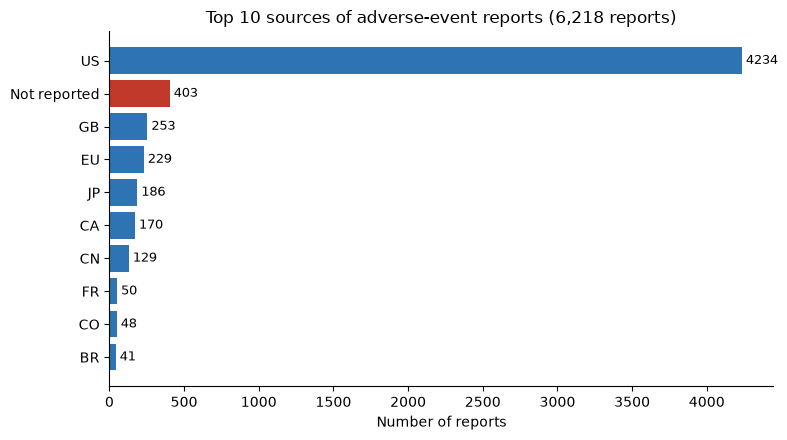

In [3]:
# Exercise 1: a sorted horizontal bar chart with value labels.
TEXT_COLUMNS = {"safety_report_id": str, "serious": str,
                "patient_age_unit": str, "country": str, "event_date": str}
df = pd.read_csv(os.path.join(RAW, "adverse_events_10k.csv"), dtype=TEXT_COLUMNS)

top10 = df["country"].fillna("Not reported").value_counts().head(10)
print(top10)
print("share of all reports in these ten:", round(top10.sum() / len(df) * 100, 1), "%")

plot_data = top10.sort_values()          # smallest first, so the largest is on top
colours = [HIGHLIGHT if name == "Not reported" else BLUE for name in plot_data.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_data.index, plot_data.values, color=colours)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("Top 10 sources of adverse-event reports (6,218 reports)")
ax.set_xlabel("Number of reports")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "ex1_top10_countries.png"), dpi=150, bbox_inches="tight")
plt.show()


## Exercise 2 · Intermediate — "Do the most-reported drugs have the most serious reports?"

The Pharmacovigilance Lead asks whether drugs with more reports also have a higher
share of serious ones. Two numbers per drug calls for a scatter plot: one dot per
drug with at least 30 reports. Label the dots that matter, not all of them.


drugs plotted: 32
correlation between reports and serious share: -0.156


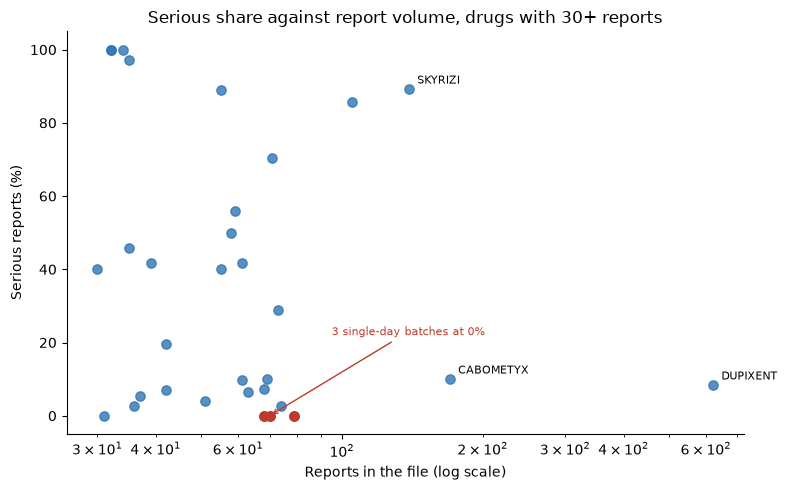

                          reports  serious_pct
drug_name                                     
DUPIXENT                      621          8.4
CABOMETYX                     170         10.0
SKYRIZI                       139         89.2
RYALTRIS                       79          0.0
OXERVATE                       70          0.0
POLYETHYLENE GLYCOL 3350       68          0.0


In [4]:
# Exercise 2: a scatter plot of two numeric measures, with selective labels.
df["is_serious"] = df["serious"].map({"1": 1.0, "2": 0.0})
by_drug = df.groupby("drug_name").agg(
    reports=("safety_report_id", "count"),
    serious_share=("is_serious", "mean"),
)
busy = by_drug[by_drug["reports"] >= 30].copy()
busy["serious_pct"] = busy["serious_share"] * 100
print("drugs plotted:", len(busy))
print("correlation between reports and serious share:",
      round(busy["reports"].corr(busy["serious_share"]), 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(busy["reports"], busy["serious_pct"], s=45, color=BLUE, alpha=0.8)
ax.set_xscale("log")
ax.set_xlabel("Reports in the file (log scale)")
ax.set_ylabel("Serious reports (%)")
ax.set_ylim(-5, 105)
ax.set_title("Serious share against report volume, drugs with 30+ reports")

for name in ["DUPIXENT", "CABOMETYX", "SKYRIZI"]:
    x, y = busy.loc[name, "reports"], busy.loc[name, "serious_pct"]
    ax.annotate(name, (x, y), xytext=(6, 4), textcoords="offset points", fontsize=8)

batches = ["RYALTRIS", "OXERVATE", "POLYETHYLENE GLYCOL 3350"]
ax.scatter(busy.loc[batches, "reports"], busy.loc[batches, "serious_pct"],
           s=45, color=HIGHLIGHT, zorder=3)
ax.annotate("3 single-day batches at 0%", (70, 0), xytext=(95, 22),
            textcoords="data", fontsize=8, color=HIGHLIGHT,
            arrowprops={"arrowstyle": "->", "color": HIGHLIGHT})
to_label = ["DUPIXENT", "CABOMETYX", "SKYRIZI"] + batches
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "ex2_volume_vs_serious.png"), dpi=150, bbox_inches="tight")
plt.show()

print(busy.loc[to_label, ["reports", "serious_pct"]].round(1))


## Exercise 3 · Advanced — "Do reports from different places describe the same problems?"

Session 2.2 found that product-use errors are a much bigger share of US reports than
of reports from elsewhere. Medical Affairs wants the whole picture in one figure: for
each region, what share of its reports falls in each reaction category. A seaborn
heatmap with one light-to-dark colour scale, numbers in the cells, and a labelled
colour bar.


each column adds up to: [100.0, 100.0, 100.0]


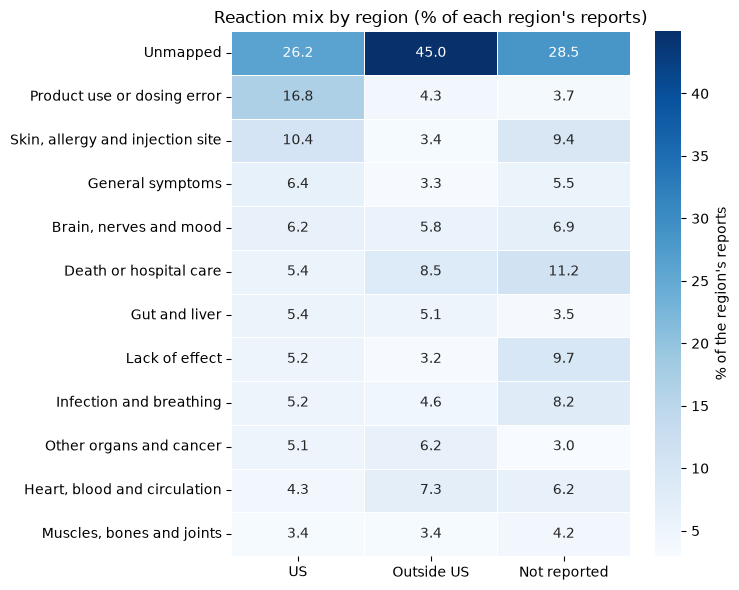

In [5]:
# Exercise 3: a seaborn heatmap of shares (each column adds up to 100).
reaction_map = pd.read_csv(os.path.join(RAW, "reaction_categories.csv"))
rx = df.merge(reaction_map, on="reaction", how="left", validate="many_to_one")
rx["reaction_category"] = rx["reaction_category"].fillna("Unmapped")
rx["region"] = "Outside US"
rx.loc[rx["country"] == "US", "region"] = "US"
rx.loc[rx["country"].isna(), "region"] = "Not reported"

mix = pd.crosstab(rx["reaction_category"], rx["region"], normalize="columns") * 100
mix = mix[["US", "Outside US", "Not reported"]].sort_values("US", ascending=False)
print("each column adds up to:", mix.sum().round(1).tolist())

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(mix, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "% of the region's reports"}, ax=ax)
ax.set_title("Reaction mix by region (% of each region's reports)")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "ex3_reaction_mix_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()


## Exercise 4 · Corporate Scenario — "This slide makes Japan look eight times safer"

A colleague's draft slide compares the serious share for the four biggest non-US
sources. Their y-axis starts at 85%, so the bars exaggerate small differences. Rebuild
it honestly, side by side with the draft so the difference is visible, and export the
honest version as a 200-dpi PNG for the slide and an SVG for the printed report.


         serious_pct  recorded_reports
country                               
GB              97.6               253
CA              94.7               169
EU              92.1               229
JP              86.6               186

bar height in the draft, GB vs JP: 12.6 vs 1.6 -> 7.9 times taller
real ratio of the shares: 1.13


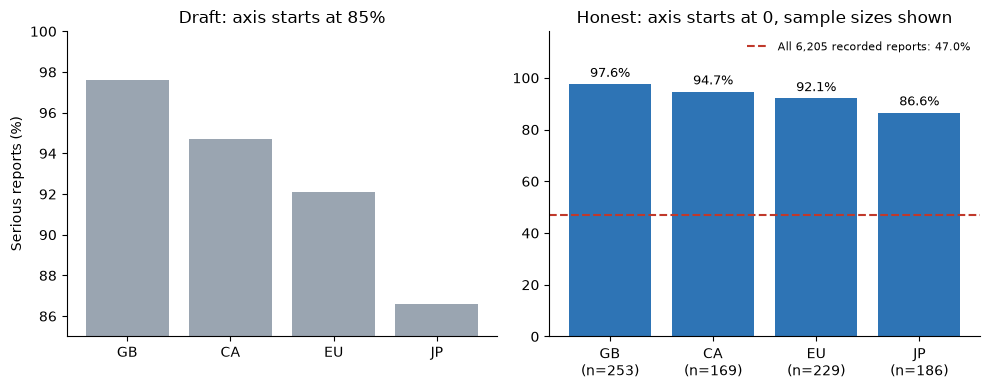

In [6]:
# Exercise 4: the misleading draft and the honest version, side by side.
four = ["GB", "CA", "EU", "JP"]
share = (df[df["country"].isin(four)].groupby("country")["is_serious"].mean() * 100)
share = share.reindex(four).round(1)
counts = df[df["country"].isin(four)].groupby("country")["is_serious"].count().reindex(four)
print(pd.DataFrame({"serious_pct": share, "recorded_reports": counts}))

bar_heights_in_draft = share - 85
print()
print("bar height in the draft, GB vs JP:", bar_heights_in_draft["GB"].round(1),
      "vs", bar_heights_in_draft["JP"].round(1),
      "->", round(bar_heights_in_draft["GB"] / bar_heights_in_draft["JP"], 1), "times taller")
print("real ratio of the shares:", round(share["GB"] / share["JP"], 2))

fig, (ax_bad, ax_good) = plt.subplots(1, 2, figsize=(10, 4))
ax_bad.bar(share.index, share.values, color=CONTEXT)
ax_bad.set_ylim(85, 100)
ax_bad.set_title("Draft: axis starts at 85%")
ax_bad.set_ylabel("Serious reports (%)")

labels = [f"{c}\n(n={n})" for c, n in counts.items()]
bars = ax_good.bar(labels, share.values, color=BLUE)
ax_good.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax_good.set_ylim(0, 118)
overall = df["is_serious"].mean() * 100
ax_good.axhline(overall, color=HIGHLIGHT, linestyle="--", linewidth=1.5,
                label=f"All 6,205 recorded reports: {overall:.1f}%")
ax_good.legend(loc="upper right", fontsize=8, frameon=False)
ax_good.set_title("Honest: axis starts at 0, sample sizes shown")
for ax in (ax_bad, ax_good):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


In [7]:
# Export only the honest chart, at slide and print quality.
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, share.values, color=BLUE)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_ylim(0, 118)
ax.axhline(overall, color=HIGHLIGHT, linestyle="--", linewidth=1.5,
           label=f"All 6,205 recorded reports: {overall:.1f}%")
ax.legend(loc="upper right", fontsize=8, frameon=False)
ax.set_ylabel("Serious reports (%)")
ax.set_title("Serious share, four largest non-US sources")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

png_path = os.path.join(CHART_DIR, "ex4_serious_share_honest.png")
svg_path = os.path.join(CHART_DIR, "ex4_serious_share_honest.svg")
fig.savefig(png_path, dpi=200, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.close(fig)
for p in (png_path, svg_path):
    print(os.path.basename(p), "| exists:", os.path.exists(p))


ex4_serious_share_honest.png | exists: True
ex4_serious_share_honest.svg | exists: True


## Exercise 5 · Interview Challenge — A chart-saving function that never leaks

Write `save_bar_chart(values, title, path)`. `values` is a pandas Series (labels in
the index). Save a horizontal bar chart to `path`, creating the folder if needed, and
return the path. Rules: it must close its figure (calling it 50 times must leave no
open figures), it must not change `values`, and an empty Series must still produce a
file, showing the text "No data", not raise an error.


In [8]:
# Exercise 5: a safe, reusable chart function.
def save_bar_chart(values, title, path):
    """Save a horizontal bar chart of a Series to path; return the path."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    try:
        if len(values) == 0:
            ax.text(0.5, 0.5, "No data", ha="center", va="center", fontsize=14)
            ax.set_axis_off()
        else:
            ordered = values.sort_values()
            ax.barh(ordered.index.astype(str), ordered.values, color=BLUE)
            ax.spines[["top", "right"]].set_visible(False)
        ax.set_title(title)
        fig.tight_layout()
        fig.savefig(path, dpi=120, bbox_inches="tight")
    finally:
        plt.close(fig)
    return path


plt.close("all")
reactions = df["reaction"].value_counts().head(5)
before = reactions.copy()

out = save_bar_chart(reactions, "Top 5 first reactions",
                     os.path.join(CHART_DIR, "ex5", "top5_reactions.png"))
print("saved:", os.path.relpath(out, REPO_ROOT), "| exists:", os.path.exists(out))
print("input unchanged:", reactions.equals(before))

empty = save_bar_chart(reactions.iloc[0:0], "Nothing to show",
                       os.path.join(CHART_DIR, "ex5", "empty.png"))
print("empty Series saved:", os.path.exists(empty))

for i in range(50):
    save_bar_chart(reactions, "repeat", os.path.join(CHART_DIR, "ex5", "repeat.png"))
print("open figures after 50 calls:", len(plt.get_fignums()))


saved: data/processed/charts/ex5/top5_reactions.png | exists: True
input unchanged: True
empty Series saved: True
open figures after 50 calls: 0


---
### Grading notes

- **Warm-Up:** one figure, two axes (`len(fig.axes)` is 2), and the PNG exists after
  `savefig`. Check that the line chart's y-axis starts at 0 and that the legend sits
  outside the lines. The teaching point: `fig` is the whole picture, each `ax` is one
  chart, and every `ax.set_...` call styles only that chart.
- **Exercise 1:** US 4,234, Not reported 403, GB 253, EU 229, JP 186, CA 170, CN 129,
  FR 50, CO 48, BR 41; the ten cover 92.4% of reports. Look for: `fillna("Not reported")`
  so the 403 are not lost, a horizontal chart sorted so the biggest is on top, values on
  the bars, and an axis label. "Not reported" in the highlight colour is a good choice, not
  a requirement. A student who uses a pie for ten categories has missed the
  chart-selection point.
- **Exercise 2:** 32 drugs; the correlation between report volume and serious share is
  −0.156, which is weak: more reports does not mean more serious reports. A log x-axis is
  needed because DUPIXENT (621) would otherwise squash everyone else into one corner.
  Four drugs sit at 0%: RYALTRIS, OXERVATE and POLYETHYLENE GLYCOL 3350 are single-day
  batches, and CONTRAVE (31 reports on 2 dates) is not, so a student who says "every 0%
  is a batch" has over-generalised. Three drugs sit at 100% (DAPAGLIFLOZIN, OSIMERTINIB,
  VENCLEXTA). Selective labels, not 32 of them.
- **Exercise 3:** every column adds up to 100 (`normalize="columns"`). The heatmap must
  use one light-to-dark colour scale (`Blues`), not a rainbow, and must say what the
  numbers are on the colour bar. Product use or dosing error is 16.8% of US reports and
  4.3% outside the US; Unmapped is 45.0% of reports from outside the US. A student who
  normalises by rows has answered a different question ("where do this category's
  reports come from?"), which is wrong for this request.
- **Exercise 4:** shares GB 97.6, CA 94.7, EU 92.1, JP 86.6 (CA's 169 is recorded
  reports; one CA report has no seriousness). With the axis at 85%, GB's bar is 12.6
  units tall and JP's 1.6: **7.9 times** taller, for shares whose real ratio is 1.13.
  The honest chart starts at 0, shows the sample sizes and the 47.0% reference line for
  all 6,205 recorded reports. Both files must exist; the PNG at `dpi=200`, the SVG with
  no dpi (it is a vector format, so it scales without blurring).
- **Exercise 5:** the input is unchanged, the empty Series produces a file, and 50
  calls leave **0** open figures. A solution without `plt.close(fig)` passes the first two
  checks and fails the third (matplotlib warns once more than 20 figures are open, and
  memory grows on every call). `try` / `finally` closes the figure even if saving fails.
